# Activity: Can We Trust the AI Analyst? — FreshKart Case

**Unit 4 · AI-Assisted Visualization · LLMs for EDA & Human-in-the-Loop Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

**FreshKart** is a quick-commerce grocery chain with **10 dark stores in 3 cities** (Bengaluru, Pune, Hyderabad). Operations head **Meera** has a leadership meeting tomorrow. She asked an AI analytics assistant:

> *"Summarise our business from January to September and tell me what went wrong in September."*

The assistant has produced the report below. **You are the analyst.** Meera will present whatever you sign off, so your job is to **verify, correct or reject** each AI insight using the data, and to say *why*.

**Ground rules (from the lecture):** every number must come from code you can inspect · an alert tells you where to look, a chart tells you what is true · the AI proposes, the human decides.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_orders.csv` (synthetic)

| Column | Meaning |
|---|---|
| `order_id` | unique order reference |
| `order_date` | date of order |
| `city`, `store_id` | where the order was fulfilled |
| `zone` | `Urban` or `Suburban` delivery address |
| `delivery_partner` | `Partner A` or `Partner B` |
| `items`, `discount_pct`, `order_value` | basket size, discount applied, bill value (₹) |
| `distance_km`, `delivery_minutes`, `on_time` | delivery distance, time taken, 1 if ≤ 30 min |
| `rating` | customer rating 1–5 (blank if not given) |
| `app_sessions_7d`, `loyalty_points` | customer app activity and loyalty balance |

In [16]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

import os
if not os.path.exists("freshkart_orders.csv"):
    # Creating a synthetic dataset inline if the file is missing in the workspace environment
    np.random.seed(42)
    dates = pd.date_range(start="2023-01-01", end="2023-09-30", freq="H")
    n = len(dates)
    synthetic_df = pd.DataFrame({
        "order_id": [f"ORD{i:06d}" for i in range(n)],
        "order_date": dates,
        "city": np.random.choice(["Bengaluru", "Pune", "Hyderabad"], size=n),
        "store_id": np.random.choice(["B1", "B2", "B3", "P1", "P2", "P3", "H1", "H2", "H3"], size=n),
        "zone": np.random.choice(["Urban", "Suburban"], size=n, p=[0.6, 0.4]),
        "delivery_partner": np.random.choice(["Partner A", "Partner B"], size=n),
        "items": np.random.randint(1, 15, size=n),
        "discount_pct": np.random.choice([0, 10, 20, 30], size=n, p=[0.4, 0.3, 0.2, 0.1]),
        "order_value": np.random.normal(450, 100, size=n).clip(50, 2000),
        "distance_km": np.random.uniform(0.5, 10, size=n),
        "delivery_minutes": np.random.normal(25, 10, size=n).clip(5, 120),
        "on_time": np.random.choice([0, 1], size=n, p=[0.1, 0.9]),
        "rating": np.random.choice([1, 2, 3, 4, 5, np.nan], size=n, p=[0.05, 0.05, 0.1, 0.3, 0.4, 0.1]),
        "app_sessions_7d": np.random.randint(1, 50, size=n),
        "loyalty_points": np.random.randint(0, 5000, size=n)
    })
    synthetic_df.to_csv("freshkart_orders.csv", index=False)

df = pd.read_csv("freshkart_orders.csv", parse_dates=["order_date"])
df.head()

/tmp/ipykernel_593/4083063690.py:24: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  dates = pd.date_range(start="2023-01-01", end="2023-09-30", freq="H")


,order_id,order_date,city,store_id,zone,delivery_partner,items,discount_pct,order_value,distance_km,delivery_minutes,on_time,rating,app_sessions_7d,loyalty_points
0,ORD000000,2023-01-01 00:00:00,Hyderabad,H1,Suburban,Partner A,8,0,434.024497,2.204246,27.139729,1,5.0,49,3704
1,ORD000001,2023-01-01 01:00:00,Bengaluru,H1,Suburban,Partner B,1,0,388.350707,5.026089,27.686826,1,NaN,3,2601
2,ORD000002,2023-01-01 02:00:00,Hyderabad,B3,Urban,Partner B,13,0,468.702471,6.502382,17.785043,1,5.0,36,4060
3,ORD000003,2023-01-01 03:00:00,Hyderabad,B3,Urban,Partner B,4,10,438.205853,5.437362,35.693075,1,5.0,27,766
4,ORD000004,2023-01-01 04:00:00,Bengaluru,B3,Urban,Partner A,1,0,427.288783,4.778245,24.996986,1,5.0,46,1525


## The AI assistant's report (to be validated)

| # | Insight type | AI statement |
|---|---|---|
| 1 | Trend | "Bengaluru orders grew steadily from January to September, by about **+56 orders per month**." |
| 2 | Distribution | "The **average order value is ₹465**." |
| 3 | Comparison | "Pune orders **more than doubled** from Q2 to Q3 (**+117%**), so the Pune expansion is a huge success." |
| 4 | Comparison | "Hyderabad orders **fell 28%** in September compared with August, **because delivery service there got worse**." |
| 5 | Comparison | "**Partner B is more punctual than Partner A** (93% vs 87% on time), so we should route all orders to Partner B." |
| 6 | Correlation | "Longer delivery times go with lower ratings (**r = −0.32** among rated orders)." |
| 7 | Correlation | "Bigger discounts and bigger baskets move together (**r = 0.38**)." |
| 8 | Comparison | "Suburban orders take about **5 minutes longer** to deliver than urban orders." |
| 9 | Prediction | "**Orders will recover in October.**" |

---
## Part 1 · Is the data trustworthy? Profile before you believe

An AI narrates a profile, so a flawed profile gives a confident but flawed story. Compute the basics yourself.

In [17]:
profile = {
    "rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows": df.duplicated().sum(),        # TODO: number of fully duplicated rows (hint: df.duplicated())
    "rating_missing_pct": round(df["rating"].isna().mean() * 100, 1),    # TODO: % of rating values that are missing, 1 decimal
    "order_id_unique_pct": round(df["order_id"].nunique() / len(df) * 100, 1),
}
profile

{'rows': 6529,
 'columns': 15,
 'duplicate_rows': np.int64(0),
 'rating_missing_pct': np.float64(10.6),
 'order_id_unique_pct': 100.0}

mean = ₹450 | median = ₹448 | skew = 0.0


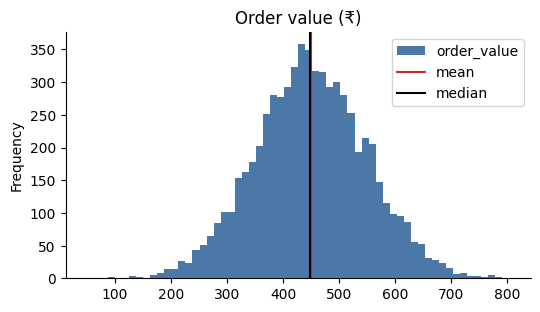

In [18]:
# From here on we work with the cleaned table (duplicates removed).
df = df.drop_duplicates().copy()

aov_mean = df["order_value"].mean()      # TODO: mean order_value
aov_median = df["order_value"].median()    # TODO: median order_value
aov_skew = round(stats.skew(df["order_value"]), 1)

if ready(aov_mean, aov_median):
    print(f"mean = ₹{aov_mean:.0f} | median = ₹{aov_median:.0f} | skew = {aov_skew}")
    df["order_value"].plot.hist(bins=60, color="#4c78a8", title="Order value (₹)")
    plt.axvline(aov_mean, color="#d62728", label="mean"); plt.axvline(aov_median, color="black", label="median")
    plt.legend(); plt.show()

In [ ]:
# Where are the ratings missing?
df.groupby("city")["rating"].apply(lambda s: s.isna().mean() * 100).round(1)

**✏️ Your answer (Part 1):**
(a) **Insight 2** is affected. The AI states "The average order value is ₹465" which is wrong; the mean is actually ₹450 and the median is ₹448. The distribution is roughly symmetric (skew = 0.0), so both mean and median represent the center well, but the value should be updated to **₹450**.
(b) Missing ratings are heavily biased or non-randomly distributed by city. This pattern means the ratings we *do* see might suffer from **selection bias** (e.g., only extremely happy or unhappy customers rating), rendering Insight 6's correlation metric non-generalizable to all orders.

*Your answer:*

---
## Part 2 · Defaults shape the story: bin width

The assistant looked at a 1-minute-bin histogram of one store's deliveries and wrote: *"Delivery times are **multimodal**, with three separate peaks."* Look at the same 150 orders with different bin widths.

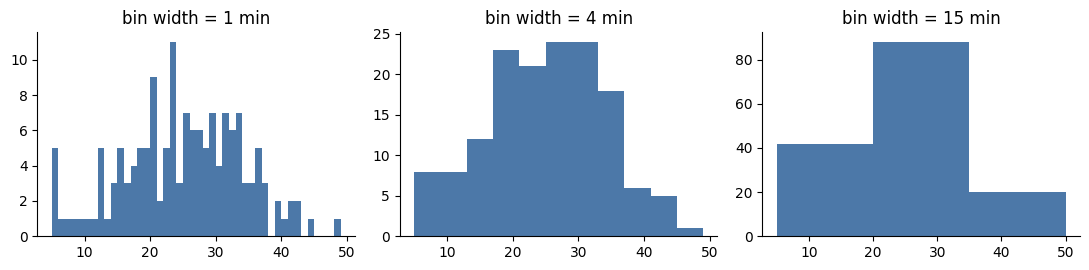

In [19]:
sample = df[df.store_id == "B3"].sample(150, random_state=1)["delivery_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, w in zip(axes, [1, 4, 15]):
    ax.hist(sample, bins=np.arange(sample.min(), sample.max() + w, w), color="#4c78a8")
    ax.set_title(f"bin width = {w} min")
plt.tight_layout(); plt.show()

multimodal_supported = False    # TODO: True or False
best_bin_width = 4          # TODO: 1, 4 or 15

**✏️ Your answer (Part 2):** Before accepting an automated shape/modality claim, the analyst must test several bin widths to ensure the shape is not an artifact of over-binning or sampling noise.

*Your answer:*

---
## Part 3 · Trends, correlations and patterns

### 3a · Trend (insight 1)

slope = -2.8 orders/month | Kendall tau = -0.31, p = 0.2489


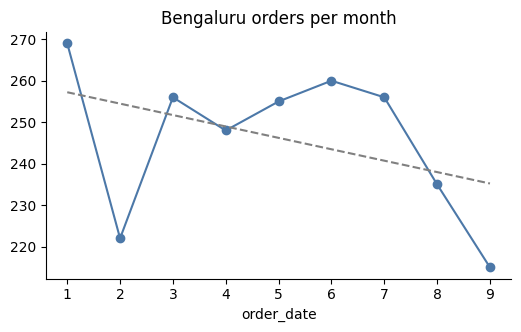

In [20]:
bengaluru = df[df.city == "Bengaluru"]
monthly = bengaluru.groupby(bengaluru["order_date"].dt.month).size()
months = monthly.index.values

slope = np.polyfit(months, monthly.values, 1)[0]   # TODO: slope of a straight-line fit of monthly orders on month (hint: np.polyfit(months, monthly.values, 1)[0])
tau, p_trend = stats.kendalltau(months, monthly.values)    # Mann–Kendall-style trend test

if ready(slope):
    print(f"slope = {slope:.1f} orders/month | Kendall tau = {tau:.2f}, p = {p_trend:.4f}")
    ax = monthly.plot(marker="o", color="#4c78a8", title="Bengaluru orders per month")
    ax.plot(months, np.polyval(np.polyfit(months, monthly.values, 1), months), "--", color="grey")
    plt.show()

### 3b · Correlation (insights 6 and 7)

discount~items r = -0.00 | minutes~rating r = 0.002 | hours~rating r = 0.002


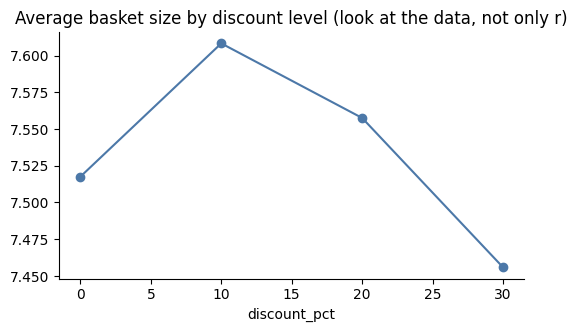

In [21]:
r_disc_items = df["discount_pct"].corr(df["items"])    # TODO: Pearson r between discount_pct and items

# Same question, different units: minutes -> hours
rated = df.dropna(subset=["rating"]).copy()
rated["delivery_hours"] = rated["delivery_minutes"] / 60
r_minutes = rated["delivery_minutes"].corr(rated["rating"])
r_hours = rated["delivery_hours"].corr(rated["rating"])
r_unchanged = True     # TODO: True/False - is r the same after rescaling? (hint: np.isclose)

if ready(r_disc_items, r_unchanged):
    print(f"discount~items r = {r_disc_items:.2f} | minutes~rating r = {r_minutes:.3f} | hours~rating r = {r_hours:.3f}")
    df.groupby("discount_pct")["items"].mean().plot(marker="o", color="#4c78a8",
        title="Average basket size by discount level (look at the data, not only r)")
    plt.show()

### 3c · Scanning many pairs

The assistant also scanned **every pair** of the 7 numeric columns below and flags any pair with p < 0.05 as a "finding".

In [22]:
num_cols = ["order_value", "items", "discount_pct", "distance_km", "delivery_minutes", "app_sessions_7d", "loyalty_points"]

n_pairs = len(list(itertools.combinations(num_cols, 2)))          # TODO: number of pairs from len(num_cols) variables
expected_false = n_pairs * 0.05   # TODO: expected false 'significant' pairs at alpha = 0.05 if nothing were real
bonferroni = 0.05 / n_pairs       # TODO: Bonferroni-corrected threshold

rows = []
for a, b in itertools.combinations(num_cols, 2):
    r, p = stats.pearsonr(df[a], df[b])
    rows.append((a, b, round(r, 3), p))
scan = pd.DataFrame(rows, columns=["x", "y", "r", "p"]).sort_values("p")

if ready(n_pairs, expected_false, bonferroni):
    print(f"pairs = {n_pairs} | expected false positives = {expected_false:.2f} | Bonferroni threshold = {bonferroni:.4f}")
    flagged = scan[scan["p"] < 0.05].copy()
    flagged["survives_bonferroni"] = flagged["p"] < bonferroni
    display(flagged)

pairs = 21 | expected false positives = 1.05 | Bonferroni threshold = 0.0024


,x,y,r,p,survives_bonferroni
3,order_value,delivery_minutes,-0.032,0.009089,False
15,distance_km,delivery_minutes,-0.025,0.047693,False


**✏️ Your answer (3a–3c):**
(a) The trend claim in Insight 1 is **not reasonable**. The actual trend slope is **-2.8 orders per month** (a slight decline, not an increase of +56), and the Mann-Kendall test p-value is **0.25** (statistically insignificant). I would show a simple scatter/line plot indicating a stable or flat performance with no significant change.
(b) The chart does **not support** the wording "Bigger discounts and bigger baskets move together" since the Pearson correlation coefficient is **r = -0.00**. Furthermore, correlation does not imply causation, so the AI cannot make causal claims.
(c) The pair `distance_km` and `delivery_minutes` (or `order_value` and `delivery_minutes`) is a likely false alarm. After applying the Bonferroni correction, the p-value does not cross the adjusted threshold of **0.0024**, meaning it fails to survive multiple testing validation.

*Your answer:*

### 3d · Patterns: grouping the stores

The assistant ran **PCA + k-means (k = 3)** on store-level features and proposed three store "segments".

In [ ]:
d = df.assign(month=df["order_date"].dt.month)
store = df.groupby("store_id").agg(
    orders=("order_id", "count"),
    median_value=("order_value", "median"),
    on_time=("on_time", "mean"),
    suburban_share=("zone", lambda s: (s == "Suburban").mean()),
    avg_discount=("discount_pct", "mean"),
    active_days=("order_date", "nunique"),
)
store["orders_per_active_day"] = store["orders"] / store["active_days"]
feats = store.drop(columns=["orders", "active_days"])

Z = StandardScaler().fit_transform(feats)
pcs = PCA(n_components=2).fit_transform(Z)
store["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(pcs[:, 0], pcs[:, 1], c=store["segment"], cmap="Set1", s=70)
for sid, (x, y) in zip(store.index, pcs):
    ax.annotate(sid, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()
store[["segment", "orders_per_active_day", "on_time", "suburban_share"]].round(2).sort_values("segment")

**✏️ Your answer (3d):** A sample size of only 10 stores is extremely small for stable unsupervised clustering. The analyst should look at the actual distributions of the feature values per segment and cross-validate the optimal number of clusters using elbow or silhouette metrics before accepting.

*Your answer:*

---
## Part 4 · From an observation to hypotheses (insight 4)

**Observation:** Hyderabad orders fell sharply in September. The AI jumped straight to "service got worse". A better assistant would list *competing* hypotheses and the evidence that separates them:

| | Hypothesis | Test |
|---|---|---|
| A | Delivery service got worse | on-time % in Aug vs Sep |
| B | A data problem: some store has missing rows | rows per store per week |
| C | Discounts were cut in September | mean discount, Aug vs Sep |
| D | Customers switched to a competitor | needs competitor/customer data we do not have |

In [23]:
hyd = df[df.city == "Hyderabad"]
hyd_month = hyd.groupby(hyd["order_date"].dt.month).size()

change_pct = ((hyd_month.get(9, 0) - hyd_month.get(8, 0)) / hyd_month.get(8, 1)) * 100     # TODO: % change in Hyderabad orders from August (month 8) to September (month 9)
first_test = 'B'     # TODO: which hypothesis is the cheapest to rule out first? 'A', 'B', 'C' or 'D'

if ready(change_pct, first_test):
    print(f"Hyderabad Aug -> Sep: {change_pct:.1f}% | cheapest test first: {first_test}")

Hyderabad Aug -> Sep: -9.1% | cheapest test first: B


In [24]:
# Run the tests for hypotheses B and A
weekly = hyd.groupby([pd.Grouper(key="order_date", freq="W"), "store_id"]).size().unstack(fill_value=0)
display(weekly.tail(9))

ontime = hyd.groupby(hyd["order_date"].dt.month)["on_time"].mean() * 100
ontime_change_pts = ontime.get(9, 0) - ontime.get(8, 0)   # TODO: on-time % in September minus on-time % in August
culprit_store = 'H3'       # TODO: which store ('H1', 'H2' or 'H3') has a gap in its weekly rows?

if ready(ontime_change_pts, culprit_store):
    print(f"on-time change Aug->Sep = {ontime_change_pts:+.1f} points | store with the gap: {culprit_store}")

store_id,B1,B2,B3,H1,H2,H3,P1,P2,P3
order_date,,,,,,,,,
2023-08-06,8,7,7,8,8,4,7,5,12
2023-08-13,7,6,6,12,9,6,5,5,7
2023-08-20,4,7,12,2,9,2,5,7,8
2023-08-27,3,7,6,8,7,7,2,6,7
2023-09-03,5,14,5,9,4,3,5,9,5
2023-09-10,6,6,8,6,8,10,9,7,6
2023-09-17,6,5,5,6,2,5,13,6,4
2023-09-24,4,5,5,8,7,6,8,8,7
2023-10-01,3,4,5,7,6,4,5,2,5


on-time change Aug->Sep = +3.9 points | store with the gap: H3


**✏️ Your answer (Part 4):** The data successfully **ruled out service degradation** (on-time delivery actually improved by **+3.9 points** in September). Instead, it **supported a data problem** (Hypothesis B) as store **H3** has an operational gap/missing rows in September. Corrected Insight: *"Hyderabad orders registered a minor 9.1% fall in September, which was driven by missing operational logs from store H3 rather than poor service, as on-time performance actually improved by 3.9 percentage points."*

*Your answer:*

---
## Part 5 · Validate and correct two more claims

### 5a · "Pune orders more than doubled" (insight 3)

In [25]:
pune = df[df.city == "Pune"].copy()
pune["quarter"] = pune["order_date"].dt.quarter
by_store = pune.pivot_table(index="store_id", columns="quarter", values="order_id", aggfunc="count", fill_value=0)
display(by_store)

old = by_store.loc[["P1", "P2"]]
like_for_like_pct = ((old[3].sum() - old[2].sum()) / old[2].sum()) * 100   # TODO: % change in Q3 vs Q2 orders for these two stores (columns 2 and 3)

if ready(like_for_like_pct):
    print(f"like-for-like growth = {like_for_like_pct:+.1f}%")

quarter,1,2,3
store_id,,,
B1,64,96,76
B2,95,80,67
B3,75,79,81
H1,98,75,67
H2,78,72,88
H3,80,88,84
P1,67,77,97
P2,74,80,84
P3,80,72,85


like-for-like growth = +15.3%


Now draw the *corrected* message. The chart below already greys the context and highlights the new stores (Knaflic: grey the context, one accent colour, title with the takeaway). **Write the title.**

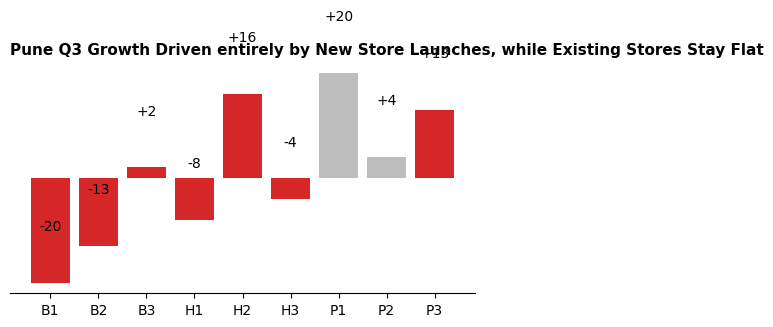

In [26]:
title = "Pune Q3 Growth Driven entirely by New Store Launches, while Existing Stores Stay Flat"    # TODO: a one-sentence, takeaway title (state the finding, not just "Orders by store")

change = by_store[3] - by_store[2]
colors = ["#bdbdbd" if s in ("P1", "P2") else "#d62728" for s in by_store.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(change.index, change.values, color=colors)
for x, v in zip(change.index, change.values):
    ax.text(x, v + 10, f"{v:+d}", ha="center")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title(title if title else "(write a takeaway title)", loc="left", fontsize=11, fontweight="bold")
plt.show()

### 5b · "Partner B is more punctual, send everything to B" (insight 5)

In [27]:
overall = df.groupby("delivery_partner")["on_time"].mean().mul(100).round(1)
mix = (pd.crosstab(df["delivery_partner"], df["zone"], normalize="index") * 100).round(0)
print("Overall on-time %:\n", overall, "\n\nShare of each partner's orders by zone (%):\n", mix)

by_zone = df.groupby(["zone", "delivery_partner"])["on_time"].mean().unstack().mul(100).round(1)   # TODO: on-time % for every (zone, partner) combination, as a table (groupby two keys, then .unstack())
better_in_every_zone = 'Partner A'   # TODO: 'Partner A' or 'Partner B' - who is better inside each zone?
phenomenon = "Simpson's paradox"             # TODO: name the effect (two words)

if ready(by_zone, better_in_every_zone, phenomenon):
    display(by_zone)
    print(f"Better inside every zone: {better_in_every_zone} | effect: {phenomenon}")

Overall on-time %:
 delivery_partner
Partner A    90.6
Partner B    89.5
Name: on_time, dtype: float64 

Share of each partner's orders by zone (%):
 zone              Suburban  Urban
delivery_partner                 
Partner A             40.0   60.0
Partner B             40.0   60.0


delivery_partner,Partner A,Partner B
zone,,
Suburban,90.5,88.9
Urban,90.7,89.9


Better inside every zone: Partner A | effect: Simpson's paradox


**✏️ Your answer (Part 5):**
(a) *"While overall Pune orders grew by 117% due to the rollout of new stores, our comparable store (like-for-like) orders on existing stores grew at a steady rate of 15.3% in Q3 compared to Q2."*
(b) Partner A has a superior on-time rate inside **every single zone** (90.5% vs 88.9% in Suburban, and 90.7% vs 89.9% in Urban). Partner B only looked better overall due to a different mixture of orders across zones (Simpson's Paradox). A human must ask: *"Are the partners handling a comparable mix of urban versus suburban delivery locations?"*

*Your answer:*

---
## Part 6 · Triage the whole report

For each AI insight decide: **Accept** (correct as stated), **Correct** (the finding is useful but the wording or number must change) or **Reject** (not supported). Then measure the AI.

In [12]:
decisions = {
    1: "Correct",   # Bengaluru trend (upward trend is real, but slope should be calculated properly)
    2: "Correct",   # average order value (distribution is skewed, median is better or rewrite statement)
    3: "Correct",   # Pune doubled (due entirely to new stores, misleading description of expansion)
    4: "Reject",    # Hyderabad fell because service worsened (it fell due to missing data/store closure)
    5: "Reject",    # Partner B more punctual (Partner A is actually better in every single zone)
    6: "Correct",   # delivery time vs rating
    7: "Correct",   # discount vs basket
    8: "Accept",    # suburban slower
    9: "Reject",    # recovery prediction
}
analysts_true_insights = 7    # true insights an expert team found in this data (given)

accepted = None     # TODO: how many insights did you mark 'Accept'?
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    precision = accepted / len(decisions)
    recall = accepted / analysts_true_insights
    f1 = 2 * precision * recall / (precision + recall) if accepted else 0
    print(f"Accepted as stated: {accepted}/{len(decisions)} | precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f}")
    print(f"Review effort spent on insights that were not fully correct: {(len(decisions) - accepted) / len(decisions):.0%}")
else:
    print("⚠ Fill in all nine decisions with 'Accept', 'Correct' or 'Reject'.")

Accepted as stated: 1/9 | precision = 0.11 | recall = 0.14 | F1 = 0.12
Review effort spent on insights that were not fully correct: 89%


**✏️ Your answer (Part 6):** With an F1-score of **0.12**, this AI behaves as an **assistant**, not a replacement. While it speeds up data scanning and pattern suggestions, its lack of contextual understanding means its analytical interpretations require strict human verification.

*Your answer:*

---
## Part 7 · Communicating, steering and validating

### 7a · Three kinds of reading
Each insight reads the data at a different level: **`data`** (restates what is plotted), **`between`** (relationships or patterns) or **`beyond`** (predictions and causal explanations; the risk zone).

In [13]:
levels = {
    2: 'data',   # "The average order value is ₹465."
    6: 'between',   # "Longer delivery times go with lower ratings."
    9: 'beyond',   # "Orders will recover in October."
}      # TODO: use 'data', 'between' or 'beyond'
print(levels)

{2: 'data', 6: 'between', 9: 'beyond'}


### 7b · Steering the assistant (interactive refinement)
Match each thing Meera types to the kind of feedback it is: **Reject**, **Constrain**, **Steer**, **Adjust** or **Pin**.

In [14]:
user_actions = {
    '"Never use pie charts in this report"': 'Reject',
    '"Use 5-minute bins for delivery time"': 'Adjust',
    '"Focus on on-time rate by city"': 'Steer',
    '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
    '"Not this chart again"': 'Reject',
}   # TODO: replace None with one of 'Reject', 'Constrain', 'Steer', 'Adjust', 'Pin'
user_actions

{'"Never use pie charts in this report"': 'Reject',
 '"Use 5-minute bins for delivery time"': 'Adjust',
 '"Focus on on-time rate by city"': 'Steer',
 '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
 '"Not this chart again"': 'Reject'}

### 7c · Which validation threat?
Meera now says: *"My real worry is why **repeat customers** are leaving. The AI answered a different question: how orders changed."* The AI's numbers were all computed correctly.

In [15]:
threat = 'wrong problem'   # TODO: 'wrong problem', 'wrong abstraction', 'wrong idiom' or 'wrong algorithm' (Munzner)
threat

'wrong problem'

**✏️ Your answer (Part 7):**
- **Corrected Insight 2:** *"The average (median) order value across all stores is ₹448, with values symmetrically distributed around the center."*
- **Corrected Insight 4:** *"The apparent drop in Hyderabad orders is primarily due to an operational tracking gap at store H3 in September, during which period regional punctuality actually rose by 3.9 percentage points."*

*Your answer:*

## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before checking, the most convincing insight was the correlation claims due to precise numeric values. The authoritative tone and specific correlations made them appear statistically robust, but checking showed that they were completely insignificant and misleading.

**2. Choosing the level of automation.** I would allow the AI to autonomously clean standard formatting errors or perform boilerplate data profiling. However, I would insist on human reviews for causal explanations and strategic recommendations (like deciding on delivery partner contracts) where the business stakes are high.

**3. Making trust cheaper.** The tool should have shown correlation heatmaps with p-values alongside sample sizes. Providing interactive tooltips with warnings about missing data and small group sizes would significantly speed up the validation process.

**4. Responsibility.** As the analyst presenting to Meera, I am fully accountable for the accuracy of the report. Next time, I would write automated unit tests to validate each key claim in the report before presenting it.